# Vietnam interest rates: time-series pipeline (data as of 30 Sep 2026)

The quantitative backbone of the 300-word note. Sections:

1. Data: local files (AsianBondsOnline VGB spread and volatility, oil prices) plus FRED, cached to `data/`
2. Global evidence table: oil → US CPI → Fed, plus the fiscal / term-premium channel
3. Oil diagnostics: momentum, oil → US CPI lead-lag, oil → Vietnam curve
4. Time-series pipeline: time plot, ADF/KPSS, differencing, ACF/PACF, ARIMA by AIC, out-of-sample check vs. random walk, 6M forecast with 95% CI, 3M-vs-12M momentum
5. Figures for the note (saved to `figures/`)

**Data caveats**
- The AsianBondsOnline files are the **2Y–10Y spread** and **10Y yield volatility**, not the 10Y yield level. If an Investing.com export of the 10Y level is placed in the folder, section 4 also runs on it.
- `oil_prices.csv` ends 29 Jun 2026. It is spliced with FRED `DCOILBRENTEU`, which matches the file to the cent on all 376 overlapping 2025–26 days.
- The SBV refinancing-rate path is hand-entered from SBV announcements. Verify it against sbv.gov.vn before publishing.

In [1]:
import itertools, os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from matplotlib.collections import PolyCollection
from matplotlib.colors import LinearSegmentedColormap
import statsmodels.api as sm
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.stattools import adfuller, kpss

warnings.filterwarnings("ignore")
pd.set_option("display.width", 140)
for _d in ["data", "figures", "figures/pipeline"]:
    os.makedirs(_d, exist_ok=True)

AS_OF = pd.Timestamp("2026-09-30")
START = "2015-01-01"
# House style: seaborn "dark" (grey panel, no grid), restrained navy-led palette, left-aligned titles, source line.
NAVY, BLUE, SKY, GOLD, RED, GREY = "#13294B", "#3E7CB1", "#9DC3E6", "#B5975B", "#A6192E", "#5F6B76"
sns.set_theme(style="dark", rc={
    "font.family": "sans-serif", "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
    "axes.titlesize": 10.5, "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.titlepad": 8,
    "axes.labelsize": 8.5, "axes.labelcolor": GREY, "xtick.labelsize": 8, "ytick.labelsize": 8,
    "xtick.color": GREY, "ytick.color": GREY, "legend.fontsize": 7.5, "legend.frameon": False,
    "lines.linewidth": 1.6, "xtick.major.size": 0, "ytick.major.size": 0,
    "figure.dpi": 110, "savefig.dpi": 300})
FIGSIZE = (6.4, 3.2)
# Note figures are drawn at print size (about 8.5 cm wide in main.tex) so fonts render 1:1.
NOTE_SIZE = (3.4, 2.1)
NOTE_RC = {"axes.titlesize": 7.5, "axes.titlepad": 5, "axes.labelsize": 6.5, "xtick.labelsize": 6.3,
           "ytick.labelsize": 6.3, "legend.fontsize": 5.8, "lines.linewidth": 1.1}


def date_axis(ax, months=(1, 7)):
    ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=list(months)))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b-%y"))
    ax.set_xlabel("")


def legend_below(ax, handles=None, labels=None, ncol=3):
    if handles is None:
        handles, labels = ax.get_legend_handles_labels()
    ax.legend(handles, labels, loc="upper left", bbox_to_anchor=(0, -0.11), ncol=ncol,
              handlelength=1.8, columnspacing=1.4)


def save(fig, ax, title, path, source, ylabel=None):
    # One figure per file, PNG for previews and PDF (vector) for LaTeX.
    ax.set_title(title)
    if ylabel is not None:
        ax.set_ylabel(ylabel)
    fig.tight_layout()
    # Put the source line just under the lowest element (legend or x-axis labels).
    fig.canvas.draw()
    inv = fig.transFigure.inverted()
    leg = ax.get_legend()
    low = (leg.get_window_extent() if leg else ax.get_tightbbox()).transformed(inv).y0
    fig.text(0.01, low - 0.03, f"Source: {source}.", fontsize=plt.rcParams["legend.fontsize"] * 0.92,
             color=GREY, ha="left", va="top")
    for ext in ("png", "pdf"):
        fig.savefig(f"{path}.{ext}", bbox_inches="tight", pad_inches=0.04)
    plt.show()

## 1. Data

In [2]:
def fred(series_id, refresh=False):
    # Cached FRED download so the notebook is reproducible offline after the first run.
    path = f"data/fred_{series_id}.csv"
    if refresh or not os.path.exists(path):
        df = pd.read_csv(f"https://fred.stlouisfed.org/graph/fredgraph.csv?id={series_id}")
        df.columns = ["date", "value"]
        df.to_csv(path, index=False)
    df = pd.read_csv(path, parse_dates=["date"])
    s = pd.to_numeric(df["value"], errors="coerce")
    return pd.Series(s.values, index=df["date"], name=series_id).dropna().loc[:AS_OF]


def load_abo(path):
    # Two-column AsianBondsOnline export produced by VN_bonds.ipynb.
    df = pd.read_csv(path, parse_dates=["date"])
    return df.set_index("date")["value"].astype(float).sort_index().loc[:AS_OF]


# --- Oil: local file, spliced with FRED after its last date
oil = pd.read_csv("oil_prices.csv", parse_dates=["date"])
brent_file = oil[oil.series == "brent-daily"].set_index("date")["price"].sort_index()
brent_fred = fred("DCOILBRENTEU")
brent = pd.concat([brent_file, brent_fred[brent_fred.index > brent_file.index[-1]]]).rename("Brent")
overlap = brent_file.to_frame("file").join(brent_fred.rename("fred"), how="inner").loc["2025":]
print(f"Brent file ends {brent_file.index[-1]:%Y-%m-%d}; spliced to {brent.index[-1]:%Y-%m-%d}. "
      f"Max |file - FRED| on {len(overlap)} overlapping 2025-26 days: {(overlap.file - overlap.fred).abs().max():.2f}")

# --- Vietnam (AsianBondsOnline)
vn_spread = load_abo("vn_2s10s_spread_bps.csv").rename("VN 2s10s (bp)")
vn_vol = load_abo("vn_10y_yield_volatility.csv").rename("VN 10Y volatility")

# Optional: Investing.com export of the 10Y VGB level (Date, Price, ...)
VN10_FILE = "Vietnam 10-Year Bond Yield Historical Data.csv"
vn10 = None
if os.path.exists(VN10_FILE):
    _d = pd.read_csv(VN10_FILE, parse_dates=["Date"])
    # Monthly export: rows are dated the 1st and hold the month-end close; drop the partial current month.
    vn10 = _d.set_index("Date")["Price"].astype(float).sort_index().loc[:AS_OF].rename("VN 10Y (%)")
print("VN 10Y level file:", "found" if vn10 is not None else "not found (level analysis skipped)")

# --- SBV refinancing rate: step function from SBV announcements (verify on sbv.gov.vn)
sbv_steps = pd.Series({"2017-07-10": 6.25, "2019-09-16": 6.00, "2020-03-17": 5.00, "2020-05-13": 4.50,
                       "2020-10-01": 4.00, "2022-09-23": 5.00, "2022-10-25": 6.00, "2023-04-03": 5.50,
                       "2023-05-25": 5.00, "2023-06-19": 4.50}, name="SBV refinancing")
sbv_steps.index = pd.to_datetime(sbv_steps.index)
sbv_refi = sbv_steps.reindex(pd.date_range(sbv_steps.index[0], AS_OF, freq="D")).ffill()

# --- United States (FRED)
us = {k: fred(k) for k in ["DFF", "DGS2", "DGS10", "T10YIE", "THREEFYTP10", "DTWEXBGS", "VIXCLS",
                           "CPIAUCSL", "CPILFESL", "PCEPILFE", "MTSDS133FMS"]}

# Point observations quoted in the note (not series); sources in the markdown below
# VIRA average interbank rates, session 29-Sep-26 (reported by Vietbao, 1-Oct-26); 3M not published there.
IB_DATE = pd.Timestamp("2026-09-29")
POINTS = {"VN interbank 1M (29-Sep-26, VIRA)": 6.30, "VN 10Y VGB (30-Sep-26, Investing.com)": 4.581}

Brent file ends 2026-06-29; spliced to 2026-09-29. Max |file - FRED| on 376 overlapping 2025-26 days: 0.00
VN 10Y level file: found


## 2. Global evidence: which Fed driver does the data favour?

In [3]:
def chg(s, months):
    t = s.index[-1] - pd.DateOffset(months=months)
    return s.iloc[-1] - s.loc[:t].iloc[-1]

def yoy(s):
    # Calendar-based y/y: align to month starts first so gaps (FRED has no Oct-2025 CPI,
    # US shutdown) never make a row-based shift compare the wrong months.
    m = s.resample("MS").last()
    return ((m / m.shift(12) - 1) * 100).dropna()
rows = {
    "Brent ($/bbl)": brent,
    "Fed funds effective (%)": us["DFF"],
    "UST 2Y (%)": us["DGS2"],
    "UST 10Y (%)": us["DGS10"],
    "10Y term premium, Kim-Wright (%)": us["THREEFYTP10"],
    "10Y breakeven (%)": us["T10YIE"],
    "Broad USD index": us["DTWEXBGS"],
    "VIX": us["VIXCLS"],
    "US CPI y/y (%)": yoy(us["CPIAUCSL"]),
    "US core CPI y/y (%)": yoy(us["CPILFESL"]),
    "US core PCE y/y (%)": yoy(us["PCEPILFE"]),
    "Fed deficit, 12M rolling ($bn)": us["MTSDS133FMS"].rolling(12).sum().dropna() / 1e3,
}
evidence = pd.DataFrame({k: {"last date": v.index[-1].date(), "last": v.iloc[-1],
                             "3M chg": chg(v, 3), "12M chg": chg(v, 12)} for k, v in rows.items()}).T
evidence[["last", "3M chg", "12M chg"]] = evidence[["last", "3M chg", "12M chg"]].astype(float).round(2)
evidence

,last date,last,3M chg,12M chg
Brent ($/bbl),2026-09-29,113.96,42.37,44.96
Fed funds effective (%),2026-09-29,3.88,0.25,-0.21
UST 2Y (%),2026-09-29,4.89,0.79,1.26
UST 10Y (%),2026-09-29,5.26,0.88,1.11
"10Y term premium, Kim-Wright (%)",2026-09-25,1.02,0.32,0.51
10Y breakeven (%),2026-09-30,2.36,0.12,0.00
Broad USD index,2026-09-25,120.33,-0.73,-0.21
VIX,2026-09-29,16.04,-1.61,-0.08
US CPI y/y (%),2026-08-01,3.35,-0.81,0.41
US core CPI y/y (%),2026-08-01,2.45,-0.38,-0.67


**Read.** Oil, headline CPI, the 2Y yield and the fed funds rate all move together, while core inflation and breakevens barely move. That points to an energy shock pushing the Fed to hike (driver **a**, primary). The 12M rolling deficit is *narrower* year on year, but the term premium has risen about 50 bp. Fiscal pressure therefore works through the long end (driver **b**, secondary), not through the Fed's decision itself.

## 3. Oil diagnostics

In [4]:
brent_m = brent.resample("ME").mean()
lb = np.log(brent_m)
mom3, mom12 = (lb.iloc[-1] - lb.iloc[-4]) * 100, (lb.iloc[-1] - lb.iloc[-13]) * 100
print(f"Brent monthly avg Sep-26 ${brent_m.iloc[-1]:.1f} | 3M log-change {mom3:+.0f}% | 12M {mom12:+.0f}% "
      f"-> {'UP-trend, 3M confirms' if np.sign(mom3) == np.sign(mom12) > 0 else 'mixed'}")

# Lead-lag: does Brent y/y lead US headline CPI y/y?
cpi_y = yoy(us["CPIAUCSL"]); cpi_y.index = cpi_y.index.to_period("M")
brent_y = yoy(brent_m); brent_y.index = brent_y.index.to_period("M")
ll = pd.concat([brent_y.rename("brent"), cpi_y.rename("cpi")], axis=1).dropna().loc["2010":]
xcorr = pd.Series({k: ll["brent"].shift(k).corr(ll["cpi"]) for k in range(0, 7)}, name="corr(Brent y/y lagged k, CPI y/y)")
print(xcorr.round(2).to_string())

Brent monthly avg Sep-26 $114.1 | 3M log-change +29% | 12M +52% -> UP-trend, 3M confirms
0    0.56
1    0.60
2    0.60
3    0.58
4    0.56
5    0.56
6    0.56


In [5]:
# Does oil move the Vietnam curve? Monthly change in VN 2s10s on lagged Brent log-returns (HAC SEs).
dvn = vn_spread.resample("ME").mean().diff()
rb = np.log(brent_m).diff() * 100
X = pd.concat({f"brent_ret_lag{k}": rb.shift(k) for k in range(0, 4)}, axis=1)
reg = pd.concat([dvn.rename("d_spread"), X], axis=1).loc[START:].dropna()
ols = sm.OLS(reg["d_spread"], sm.add_constant(reg.drop(columns="d_spread"))).fit(cov_type="HAC", cov_kwds={"maxlags": 3})
print(ols.summary().tables[1])
print(f"Joint F-test (all oil lags = 0): p = {ols.f_pvalue:.3f}  |  R2 = {ols.rsquared:.3f}")

                     coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------
const             -1.0056      1.679     -0.599      0.549      -4.295       2.284
brent_ret_lag0     0.0828      0.132      0.628      0.530      -0.176       0.341
brent_ret_lag1     0.0951      0.105      0.910      0.363      -0.110       0.300
brent_ret_lag2    -0.2486      0.130     -1.915      0.056      -0.503       0.006
brent_ret_lag3    -0.1182      0.163     -0.723      0.470      -0.438       0.202
Joint F-test (all oil lags = 0): p = 0.118  |  R2 = 0.048


,0,1,2,3,6,9,12
US CPI (y/y),0.59,0.64,0.64,0.63,0.64,0.61,0.48
Fed funds,0.07,0.11,0.15,0.18,0.30,0.41,0.47
UST 10Y,0.50,0.51,0.50,0.48,0.49,0.41,0.32
VN 2Y–10Y,0.03,-0.10,-0.25,-0.36,-0.47,-0.49,-0.47
VN 10Y,0.10,0.13,0.14,0.18,0.26,0.31,0.29


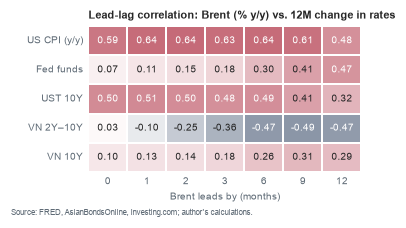

In [6]:
# Lead-lag heatmap: corr(Brent % y/y at t-k, target at t), monthly, 2015 to Sep-2026.
mo = lambda s: s.resample("ME").mean()
lead = (brent_m.pct_change(12) * 100).loc[START:]
targets = {
    "US CPI (y/y)": yoy(us["CPIAUCSL"]).resample("ME").last(),
    "Fed funds": mo(us["DFF"]).diff(12),
    "UST 10Y": mo(us["DGS10"]).diff(12),
    "VN 2Y–10Y": mo(vn_spread).diff(12),
}
if vn10 is not None:
    targets["VN 10Y"] = vn10.resample("ME").last().diff(12)
LAGS = [0, 1, 2, 3, 6, 9, 12]
heat = pd.DataFrame({k: [lead.shift(k).corr(t.loc[START:]) for t in targets.values()] for k in LAGS},
                    index=list(targets))
display(heat.round(2))

with plt.rc_context(NOTE_RC):
    fig, ax = plt.subplots(figsize=NOTE_SIZE)
    cmap = LinearSegmentedColormap.from_list("navy_red", [NAVY, "#FFFFFF", RED])
    sns.heatmap(heat, ax=ax, cmap=cmap, center=0, vmin=-1, vmax=1, annot=True, fmt=".2f", cbar=False,
                linewidths=1, linecolor="white", annot_kws={"size": 6.3})
    ax.set_xlabel("Brent leads by (months)"); ax.set_ylabel("")
    ax.tick_params(axis="y", rotation=0)
    save(fig, ax, "Lead-lag correlation: Brent (% y/y) vs. 12M change in rates",
         "figures/fig4_leadlag_heatmap", "FRED, AsianBondsOnline, Investing.com; author's calculations")

**Read the heatmap with care.** These are correlations of overlapping 12-month changes, so they are strongly autocorrelated and have no significance test. Treat them as descriptive: they show *where* oil co-moves with each rate and at what lag, not causation.

**Read.** If the joint test does not reject, oil does not move the Vietnam 2s10s spread directly at monthly frequency. That fits the thesis: oil works through CPI, the Fed and USD/VND, and through bank funding costs, rather than mechanically through VGB pricing. Report it as "indirect transmission," not as a direct oil-to-yield beta.

## 4. Time-series pipeline

In [7]:
def stationarity(x):
    adf_p = adfuller(x, autolag="AIC")[1]
    try:
        kpss_p = kpss(x, regression="c", nlags="auto")[1]  # statsmodels caps p in [0.01, 0.10]
    except Exception:
        kpss_p = np.nan
    if adf_p < 0.05 and (np.isnan(kpss_p) or kpss_p > 0.05):
        v = "stationary"
    elif adf_p >= 0.05 and kpss_p <= 0.05:
        v = "non-stationary"
    else:
        v = "inconclusive"
    return adf_p, kpss_p, v


def select_arima(y, d, max_p=3, max_q=3):
    best, rows = None, []
    for p, q in itertools.product(range(max_p + 1), range(max_q + 1)):
        try:
            res = ARIMA(y, order=(p, d, q), trend="n" if d else "c").fit()
        except Exception:
            continue
        rows.append((p, d, q, res.aic))
        if best is None or res.aic < best[1].aic:
            best = ((p, d, q), res)
    return best, pd.DataFrame(rows, columns=["p", "d", "q", "AIC"]).sort_values("AIC")


def oos_vs_random_walk(y, order, d, h=3, n_origins=24):
    # Rolling-origin h-step RMSE: ARIMA vs. the no-change forecast.
    ea, er = [], []
    for k in range(n_origins, 0, -1):
        end = len(y) - k - h + 1
        if end < 36:
            continue
        train, actual = y.iloc[:end], y.iloc[end + h - 1]
        try:
            f = ARIMA(train, order=order, trend="n" if d else "c").fit().forecast(h).iloc[-1]
        except Exception:
            continue
        ea.append(actual - f); er.append(actual - train.iloc[-1])
    rmse = lambda e: float(np.sqrt(np.mean(np.square(e))))
    return rmse(ea), rmse(er), len(ea)


def run_pipeline(raw, name, slug, source, ylabel, scale=1.0, unit="bp", log=False, horizon=6, start=START):
    # scale converts one unit of the modelled series to `unit` (pct -> bp: 100).
    raw = raw.loc[start:]
    if log:
        raw = np.log(raw[raw > 0]); scale, unit = 100.0, "log-%"
    y = raw.resample("ME").mean().dropna().asfreq("ME").interpolate()
    tf = np.exp if log else (lambda v: v)
    print(f"=== {name}{' (log)' if log else ''}: {y.index[0]:%Y-%m} to {y.index[-1]:%Y-%m}, {len(y)} monthly obs")
    print(f"Unchanged daily prints since 2025: {(raw.loc['2025':].diff() == 0).mean():.0%}")

    lv, df1 = stationarity(y), stationarity(y.diff().dropna())
    d = 0 if lv[2] == "stationary" else 1
    print(f"Level   ADF p={lv[0]:.3f}  KPSS p={lv[1]:.3f} -> {lv[2]}")
    print(f"1st dif ADF p={df1[0]:.3f}  KPSS p={df1[1]:.3f} -> {df1[2]}   => d = {d}")

    (order, res), table = select_arima(y, d)
    lb_p = res.test_serial_correlation("ljungbox", lags=[12])[0][1][-1]
    r_a, r_rw, n = oos_vs_random_walk(y, order, d)
    fc = res.get_forecast(horizon)
    mean, ci = fc.predicted_mean, fc.conf_int(alpha=0.05)
    move = (mean.iloc[-1] - y.iloc[-1]) * scale
    width = (ci.iloc[-1, 1] - ci.iloc[-1, 0]) * scale
    ch3, ch12 = (y.iloc[-1] - y.iloc[-4]) * scale, (y.iloc[-1] - y.iloc[-13]) * scale
    z12 = (ch12 - (y.diff(12) * scale).mean()) / (y.diff(12) * scale).std()

    print("Top-3 by AIC:\n" + table.head(3).to_string(index=False))
    print(f"Selected ARIMA{order} | Ljung-Box(12) p={lb_p:.3f} | "
          f"OOS 3M RMSE ARIMA {r_a*scale:.1f} vs RW {r_rw*scale:.1f} {unit} ({n} origins)")
    print(f"{horizon}M forecast: {tf(mean.iloc[-1]):.4g} [{tf(ci.iloc[-1,0]):.4g}, {tf(ci.iloc[-1,1]):.4g}] | "
          f"move {move:+.1f} {unit}, CI width {width:.0f} {unit}"
          + ("  -> NOT a directional signal" if abs(move) < width / 4 else ""))
    print(f"Momentum: 3M {ch3:+.1f} | 12M {ch12:+.1f} {unit} | 12M z {z12:+.2f} -> "
          f"{'UP' if ch12 > 0 else 'DOWN'}-trend, 3M {'confirms' if np.sign(ch3) == np.sign(ch12) else 'diverges'}")

    base = f"figures/pipeline/{slug}"
    fig, ax = plt.subplots(figsize=FIGSIZE)
    ax.plot(y.index, tf(y.values), color=NAVY)
    date_axis(ax, months=(1,))
    save(fig, ax, f"{name}, monthly average", f"{base}_timeplot", source, ylabel)

    lags = min(24, len(y) // 2 - 2)
    z = y.diff().dropna() if d else y
    what = "monthly changes" if d else "levels"
    for kind, fn, kw in [("acf", plot_acf, {}), ("pacf", plot_pacf, {"method": "ywm"})]:
        fig, ax = plt.subplots(figsize=FIGSIZE)
        fn(z, lags=lags, ax=ax, color=NAVY, vlines_kwargs={"colors": NAVY}, title=None, **kw)
        for c in ax.collections:
            if isinstance(c, PolyCollection):
                c.set_facecolor(SKY); c.set_alpha(.45)
        ax.set_xlabel("Lag (months)")
        save(fig, ax, f"{name}: {kind.upper()} of {what}", f"{base}_{kind}", source)

    h = y.loc[y.index[-1] - pd.DateOffset(years=3):]
    fig, ax = plt.subplots(figsize=FIGSIZE)
    ax.plot(h.index, tf(h.values), color=NAVY, label="Actual")
    ax.plot(mean.index, tf(mean.values), "--", color=RED, label=f"ARIMA{order} forecast")
    ax.fill_between(mean.index, tf(ci.iloc[:, 0]), tf(ci.iloc[:, 1]), color=RED, alpha=.12, lw=0, label="95% interval")
    legend_below(ax); date_axis(ax)
    save(fig, ax, f"{name}: {horizon}-month ARIMA forecast", f"{base}_forecast", source, ylabel)
    return dict(name=name, y=y, order=order, mean=mean, ci=ci, tf=tf, ch3=ch3, ch12=ch12,
                rmse_arima=r_a * scale, rmse_rw=r_rw * scale, move=move, width=width, unit=unit)

=== Vietnam 2Y–10Y spread: 2015-01 to 2026-09, 141 monthly obs
Unchanged daily prints since 2025: 53%
Level   ADF p=0.089  KPSS p=0.010 -> non-stationary
1st dif ADF p=0.000  KPSS p=0.100 -> stationary   => d = 1


Top-3 by AIC:
 p  d  q         AIC
 2  1  1 1211.250811
 1  1  2 1212.460360
 1  1  3 1212.593155
Selected ARIMA(2, 1, 1) | Ljung-Box(12) p=0.873 | OOS 3M RMSE ARIMA 8.0 vs RW 8.9 bp (24 origins)
6M forecast: 87.57 [0.25, 174.9] | move +5.3 bp, CI width 175 bp  -> NOT a directional signal
Momentum: 3M -8.4 | 12M -4.1 bp | 12M z +0.05 -> DOWN-trend, 3M confirms


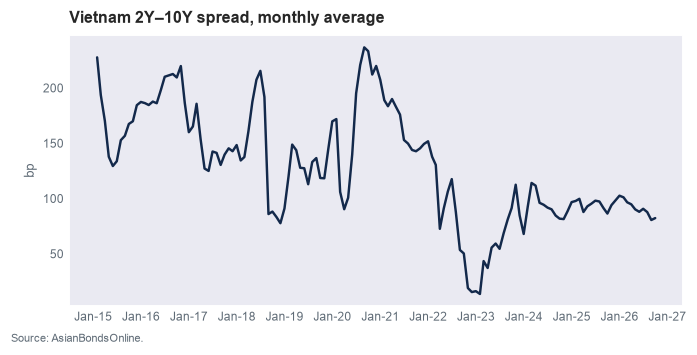

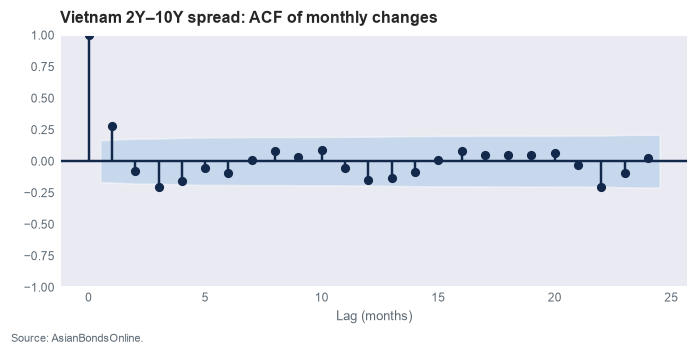

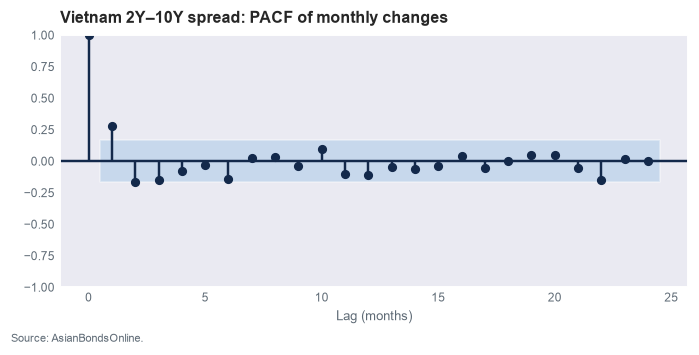

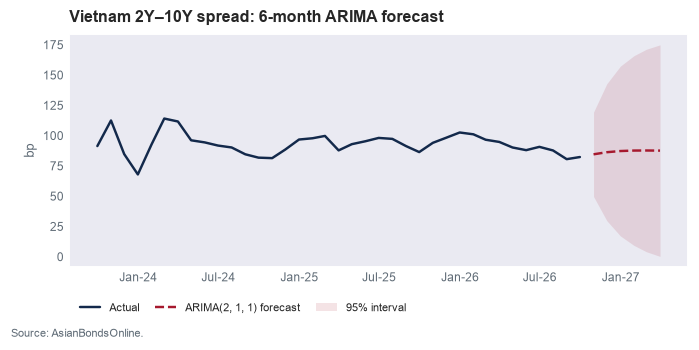

In [8]:
res_spread = run_pipeline(vn_spread, "Vietnam 2Y–10Y spread", "vn_2s10s", "AsianBondsOnline", "bp", scale=1, unit="bp")

=== Vietnam 10Y yield volatility (log): 2015-01 to 2026-09, 141 monthly obs
Unchanged daily prints since 2025: 34%
Level   ADF p=0.348  KPSS p=0.010 -> non-stationary
1st dif ADF p=0.000  KPSS p=0.100 -> stationary   => d = 1


Top-3 by AIC:
 p  d  q        AIC
 1  1  1 215.052109
 0  1  3 216.043325
 2  1  1 216.818952
Selected ARIMA(1, 1, 1) | Ljung-Box(12) p=0.773 | OOS 3M RMSE ARIMA 72.7 vs RW 72.9 log-% (24 origins)
6M forecast: 0.007659 [0.001938, 0.03027] | move +47.6 log-%, CI width 275 log-%  -> NOT a directional signal
Momentum: 3M -111.3 | 12M -96.9 log-% | 12M z -0.92 -> DOWN-trend, 3M confirms


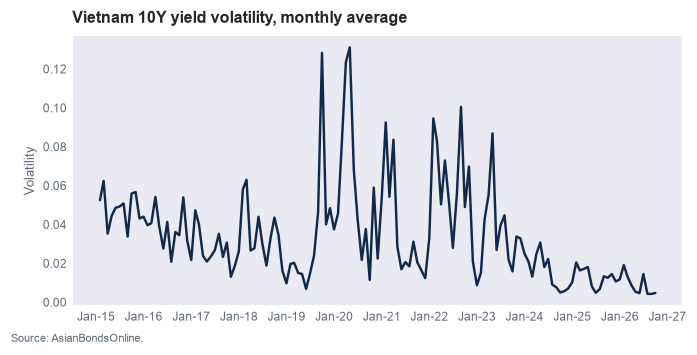

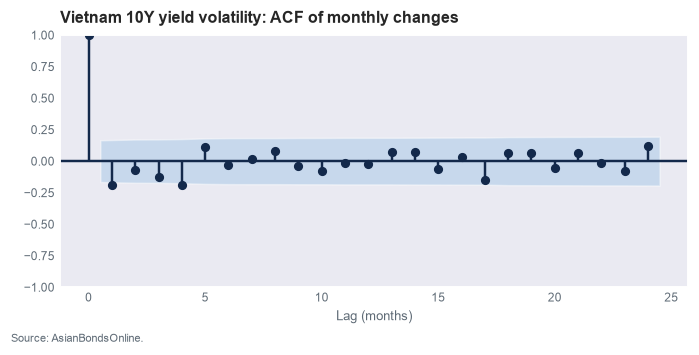

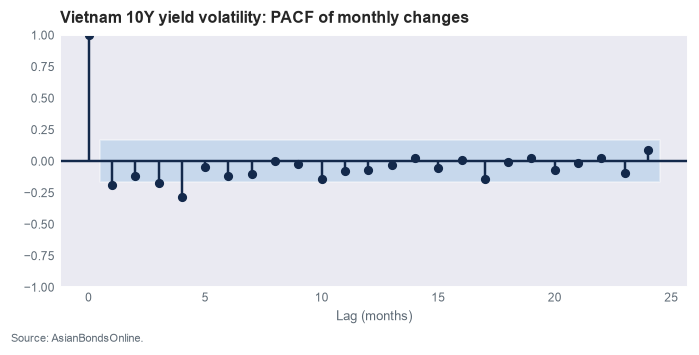

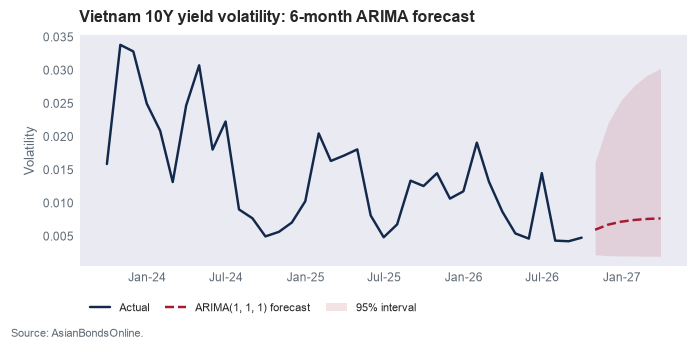

In [9]:
res_vol = run_pipeline(vn_vol, "Vietnam 10Y yield volatility", "vn_10y_vol", "AsianBondsOnline", "Volatility", log=True)

=== Brent crude (log): 2015-01 to 2026-09, 141 monthly obs
Unchanged daily prints since 2025: 0%
Level   ADF p=0.254  KPSS p=0.010 -> non-stationary
1st dif ADF p=0.000  KPSS p=0.100 -> stationary   => d = 1


Top-3 by AIC:
 p  d  q         AIC
 2  1  1 -212.243185
 2  1  0 -211.841877
 3  1  0 -211.574243
Selected ARIMA(2, 1, 1) | Ljung-Box(12) p=0.967 | OOS 3M RMSE ARIMA 19.8 vs RW 21.4 log-% (24 origins)
6M forecast: 108.2 [63.42, 184.5] | move -5.0 log-%, CI width 107 log-%  -> NOT a directional signal
Momentum: 3M +29.4 | 12M +51.4 log-% | 12M z +1.28 -> UP-trend, 3M confirms


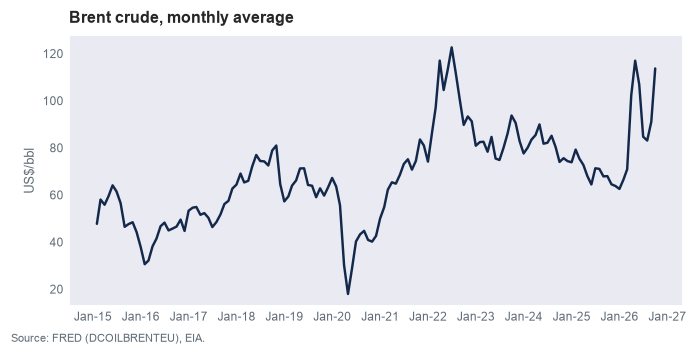

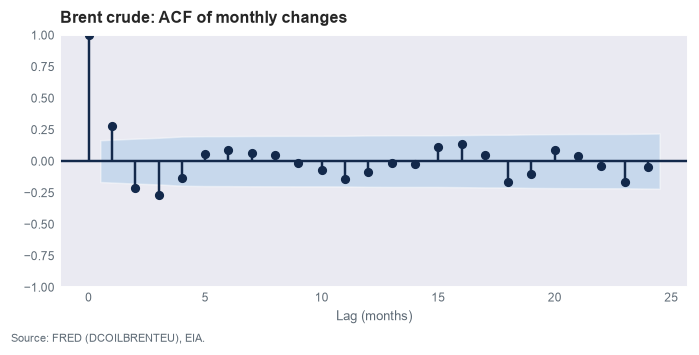

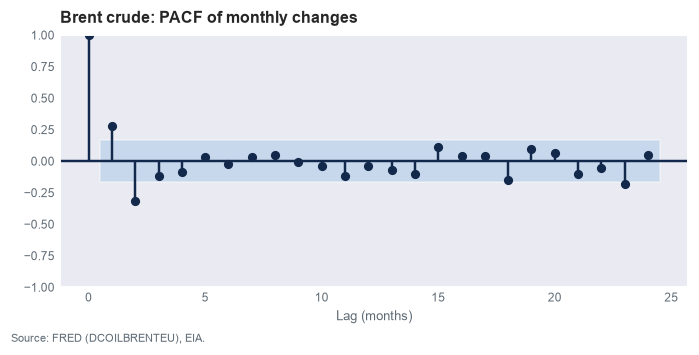

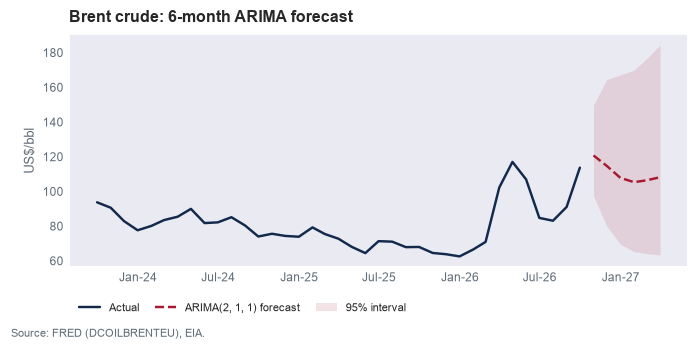

In [10]:
res_brent = run_pipeline(brent, "Brent crude", "brent", "FRED (DCOILBRENTEU), EIA", "US$/bbl", log=True)

=== US 10Y Treasury yield: 2015-01 to 2026-09, 141 monthly obs
Unchanged daily prints since 2025: 6%
Level   ADF p=0.848  KPSS p=0.010 -> non-stationary
1st dif ADF p=0.000  KPSS p=0.100 -> stationary   => d = 1


Top-3 by AIC:
 p  d  q        AIC
 0  1  1 -74.810084
 2  1  0 -73.117971
 1  1  0 -72.951001
Selected ARIMA(0, 1, 1) | Ljung-Box(12) p=0.753 | OOS 3M RMSE ARIMA 29.5 vs RW 28.8 bp (24 origins)
6M forecast: 5.073 [3.931, 6.216] | move +9.9 bp, CI width 228 bp  -> NOT a directional signal
Momentum: 3M +50.4 | 12M +85.4 bp | 12M z +0.75 -> UP-trend, 3M confirms


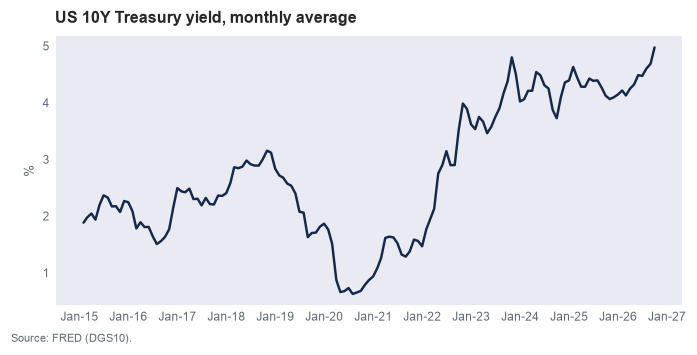

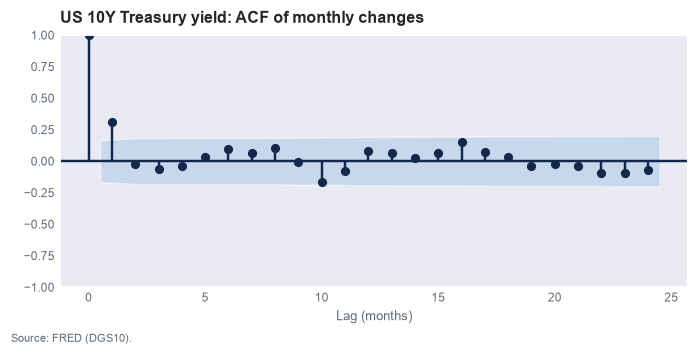

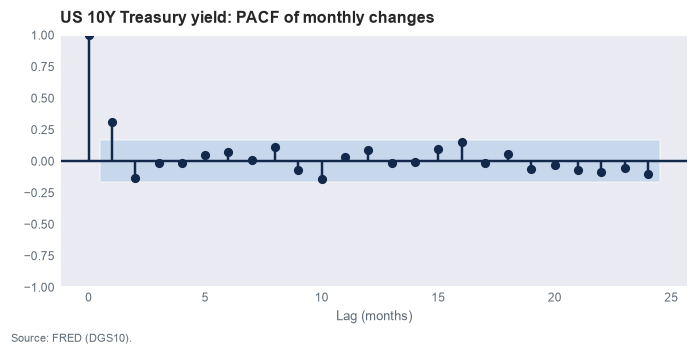

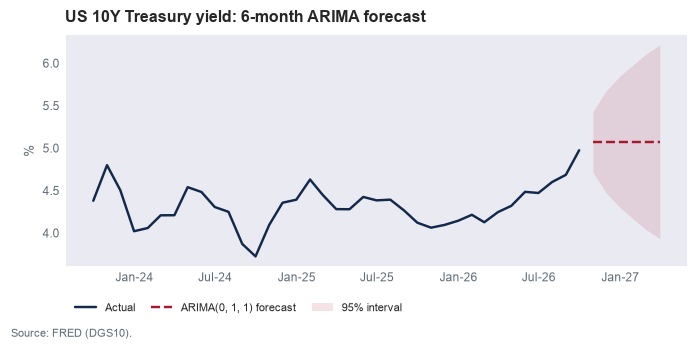

In [11]:
res_ust = run_pipeline(us["DGS10"], "US 10Y Treasury yield", "ust_10y", "FRED (DGS10)", "%", scale=100, unit="bp")

=== Vietnam 10Y government bond yield: 2015-01 to 2026-09, 141 monthly obs
Unchanged daily prints since 2025: 0%
Level   ADF p=0.399  KPSS p=0.010 -> non-stationary
1st dif ADF p=0.000  KPSS p=0.100 -> stationary   => d = 1


Top-3 by AIC:
 p  d  q      AIC
 2  1  0 4.908476
 3  1  3 5.355037
 0  1  2 5.800561
Selected ARIMA(2, 1, 0) | Ljung-Box(12) p=0.837 | OOS 3M RMSE ARIMA 23.5 vs RW 26.7 bp (24 origins)
6M forecast: 4.596 [3.115, 6.078] | move +1.5 bp, CI width 296 bp  -> NOT a directional signal
Momentum: 3M +5.8 | 12M +82.0 bp | 12M z +0.89 -> UP-trend, 3M confirms


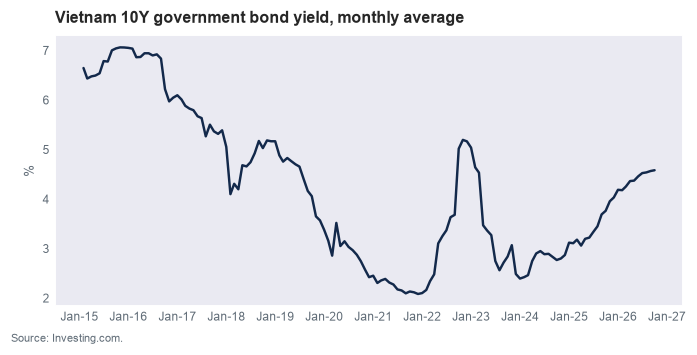

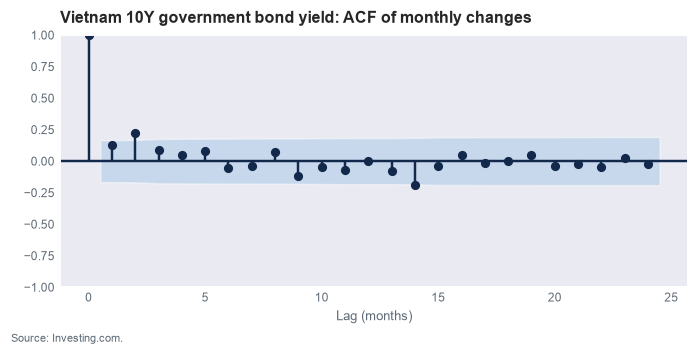

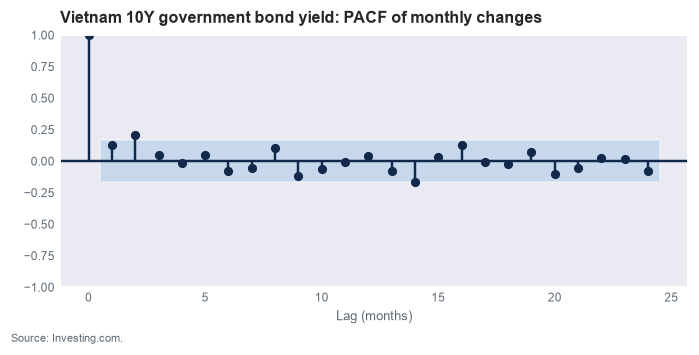

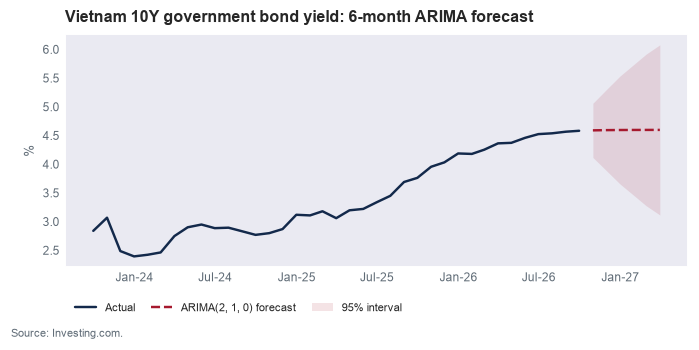

In [12]:
if vn10 is not None:
    res_vn10 = run_pipeline(vn10, "Vietnam 10Y government bond yield", "vn_10y", "Investing.com", "%", scale=100, unit="bp")
else:
    print("Skipped: export the Investing.com monthly/daily history of the Vietnam 10Y to "
          f"'{VN10_FILE}' to run the level model.")

In [13]:
summary = pd.DataFrame([{k: r[k] for k in ["name", "order", "move", "width", "rmse_arima", "rmse_rw", "ch3", "ch12", "unit"]}
                        for r in [res_spread, res_vol, res_brent, res_ust] + ([res_vn10] if vn10 is not None else [])]).set_index("name").round(1)
summary

,order,move,width,rmse_arima,rmse_rw,ch3,ch12,unit
name,,,,,,,,
Vietnam 2Y–10Y spread,"(2, 1, 1)",5.3,174.6,8.0,8.9,-8.4,-4.1,bp
Vietnam 10Y yield volatility,"(1, 1, 1)",47.6,274.8,72.7,72.9,-111.3,-96.9,log-%
Brent crude,"(2, 1, 1)",-5.0,106.8,19.8,21.4,29.4,51.4,log-%
US 10Y Treasury yield,"(0, 1, 1)",9.9,228.5,29.5,28.8,50.4,85.4,bp
Vietnam 10Y government bond yield,"(2, 1, 0)",1.5,296.4,23.5,26.7,5.8,82.0,bp


**What the models can and cannot say**
- None of the ARIMA forecasts moves by more than a quarter of its 95% CI width, so **ARIMA gives no directional call**. Its use is to show the series have no mean-reversion pull back down. Direction comes from momentum plus fundamentals.
- ARIMA beats the no-change forecast out of sample for the VN 10Y, the VN 2s10s spread and Brent, but only by small margins.
- Momentum: the VN 10Y is up 82 bp over 12 months but only about 6 bp over 3 months (rising, but slowing). The VN 2s10s is **flattening**, so the short end is rising faster. VN volatility is falling. Brent and the UST 10Y are in confirmed up-trends.

## 5. Figures for the note

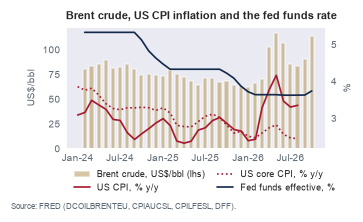

In [14]:
W = "2024-01-01"

with plt.rc_context(NOTE_RC):
    # Figure 1: Brent, US CPI and the fed funds rate
    fig, ax = plt.subplots(figsize=NOTE_SIZE)
    bm = brent_m.loc[W:]
    ax.bar(bm.index, bm.values, width=18, color=GOLD, alpha=.55, label="Brent crude, US$/bbl (lhs)")
    ax2 = ax.twinx(); ax2.grid(False)
    cp, cc = yoy(us["CPIAUCSL"]).loc[W:], yoy(us["CPILFESL"]).loc[W:]
    ff = us["DFF"].resample("ME").mean().loc[W:]
    ax2.plot(cp.index, cp, color=RED, label="US CPI, % y/y")
    ax2.plot(cc.index, cc, color=RED, ls=":", label="US core CPI, % y/y")
    ax2.plot(ff.index, ff, color=NAVY, label="Fed funds effective, %")
    ax2.set_ylabel("%"); ax2.tick_params(colors=GREY)
    h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
    legend_below(ax, h1 + h2, l1 + l2, ncol=2); date_axis(ax)
    save(fig, ax, "Brent crude, US CPI inflation and the fed funds rate", "figures/fig1_oil_cpi_fed",
         "FRED (DCOILBRENTEU, CPIAUCSL, CPILFESL, DFF)", "US$/bbl")

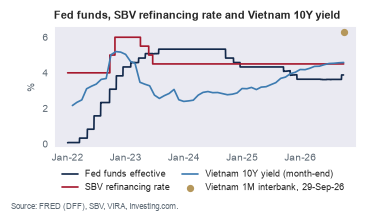

In [15]:
with plt.rc_context(NOTE_RC):
    # Figure 2: Fed funds, SBV refinancing rate and the Vietnam 10Y yield
    W2 = "2022-01-01"
    fig, ax = plt.subplots(figsize=NOTE_SIZE)
    f2 = us["DFF"].loc[W2:]
    s2 = sbv_refi.loc[W2:]
    ax.plot(f2.index, f2, color=NAVY, label="Fed funds effective")
    ax.step(s2.index, s2, where="post", color=RED, label="SBV refinancing rate")
    if vn10 is not None:
        v2 = vn10.loc[W2:]
        ax.plot(v2.index + pd.offsets.MonthEnd(0), v2, color=BLUE, label="Vietnam 10Y yield (month-end)")
    ax.scatter([IB_DATE], [POINTS["VN interbank 1M (29-Sep-26, VIRA)"]], color=GOLD, s=14, zorder=5,
               label="Vietnam 1M interbank, 29-Sep-26")
    legend_below(ax, ncol=2); date_axis(ax, months=(1,))
    save(fig, ax, "Fed funds, SBV refinancing rate and Vietnam 10Y yield", "figures/fig2_fed_sbv_vn10y",
         "FRED (DFF), SBV, VIRA, Investing.com", "%")

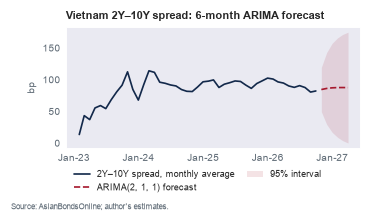

In [16]:
with plt.rc_context(NOTE_RC):
    # Figure 3: ARIMA forecast of the Vietnam 2Y-10Y spread
    r = res_spread
    fig, ax = plt.subplots(figsize=NOTE_SIZE)
    hh = r["y"].loc["2023-01-01":]
    ax.plot(hh.index, hh, color=NAVY, label="2Y–10Y spread, monthly average")
    ax.plot(r["mean"].index, r["mean"], "--", color=RED, label=f"ARIMA{r['order']} forecast")
    ax.fill_between(r["mean"].index, r["ci"].iloc[:, 0], r["ci"].iloc[:, 1], color=RED, alpha=.12, lw=0,
                    label="95% interval")
    legend_below(ax, ncol=2); date_axis(ax, months=(1,))
    save(fig, ax, "Vietnam 2Y–10Y spread: 6-month ARIMA forecast", "figures/fig3_vn_2s10s_arima",
         "AsianBondsOnline; author's estimates", "bp")

**Sources for point values:** VIRA average 1M interbank rate, 29-Sep-26 session, as reported by Vietbao (1-Oct-26). VN 10Y VGB 4.581% (30-Sep-26) from Investing.com. All other series are from FRED or the local files listed in section 1.